In [13]:

print("Medical Disease Diagnosis Using Bayesian Network")
print("My project environment is ready!")
print("Next: Dataset preparation and Bayesian Network implementation.")

Medical Disease Diagnosis Using Bayesian Network
My project environment is ready!
Next: Dataset preparation and Bayesian Network implementation.


In [14]:

from google.colab import files

uploaded = files.upload()


Saving dataset.csv to dataset (1).csv


In [15]:

import pandas as pd

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display the first five records
print("First five records:")
display(df.head())

# Display dataset size
print("\nDataset shape:")
print(df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Check disease distribution
print("\nNumber of records for each disease:")
print(df.iloc[:, 0].value_counts().head(10))


First five records:


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset shape:
(4920, 18)

Column names:
['Disease', 'Symptom_1', 'Symptom_2', 'Symptom_3', 'Symptom_4', 'Symptom_5', 'Symptom_6', 'Symptom_7', 'Symptom_8', 'Symptom_9', 'Symptom_10', 'Symptom_11', 'Symptom_12', 'Symptom_13', 'Symptom_14', 'Symptom_15', 'Symptom_16', 'Symptom_17']

Missing values in each column:
Disease          0
Symptom_1        0
Symptom_2        0
Symptom_3        0
Symptom_4      348
Symptom_5     1206
Symptom_6     1986
Symptom_7     2652
Symptom_8     2976
Symptom_9     3228
Symptom_10    3408
Symptom_11    3726
Symptom_12    4176
Symptom_13    4416
Symptom_14    4614
Symptom_15    4680
Symptom_16    4728
Symptom_17    4848
dtype: int64

Number of records for each disease:
Disease
Fungal infection       120
Allergy                120
GERD                   120
Chronic cholestasis    120
Drug Reaction          120
Peptic ulcer diseae    120
AIDS                   120
Diabetes               120
Gastroenteritis        120
Bronchial Asthma       120
Name: count, dt

In [16]:

# Make a copy so the original data remains unchanged
df_clean = df.copy()

# Remove extra spaces and standardize symptom names
symptom_cols = [
    col for col in df_clean.columns
    if col.startswith("Symptom_")
]

for col in symptom_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip().lower() if isinstance(x, str) else x
    )

# Standardize disease names
df_clean["Disease"] = df_clean["Disease"].str.strip()

# Display the cleaned data
display(df_clean.head())

print("Dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Number of diseases:", df_clean["Disease"].nunique())

,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dataset shape: (4920, 18)
Missing values: 46992
Number of diseases: 41


In [17]:

# Collect all unique symptoms from the symptom columns
all_symptoms = sorted(
    set(
        symptom.strip().lower()
        for col in symptom_cols
        for symptom in df_clean[col].dropna()
        if symptom.strip()
    )
)

print("Total unique symptoms:", len(all_symptoms))
print("\nSample symptoms:")
print(all_symptoms[:20])

# Create a binary table: 1 = symptom listed, 0 = not listed
binary_data = []

for _, row in df_clean.iterrows():
    present_symptoms = {
        str(row[col]).strip().lower()
        for col in symptom_cols
        if pd.notna(row[col]) and str(row[col]).strip()
    }

    record = {"Disease": row["Disease"]}

    for symptom in all_symptoms:
        record[symptom] = int(symptom in present_symptoms)

    binary_data.append(record)

df_binary = pd.DataFrame(binary_data)

print("\nBinary dataset shape:", df_binary.shape)
display(df_binary.head())


Total unique symptoms: 131

Sample symptoms:
['abdominal_pain', 'abnormal_menstruation', 'acidity', 'acute_liver_failure', 'altered_sensorium', 'anxiety', 'back_pain', 'belly_pain', 'blackheads', 'bladder_discomfort', 'blister', 'blood_in_sputum', 'bloody_stool', 'blurred_and_distorted_vision', 'breathlessness', 'brittle_nails', 'bruising', 'burning_micturition', 'chest_pain', 'chills']

Binary dataset shape: (4920, 132)


,Disease,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
0,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:

# Check for duplicate records
print("Duplicate rows:", df_binary.duplicated().sum())

# Check that symptom values are only 0 or 1
binary_columns = [
    col for col in df_binary.columns if col != "Disease"
]

print(
    "Only binary symptom values:",
    df_binary[binary_columns].isin([0, 1]).all().all()
)

# Check the number of records for each disease
print("\nRecords per disease:")
print(df_binary["Disease"].value_counts())

# Save the prepared dataset
df_binary.to_csv("cleaned_symptom_disease.csv", index=False)

print("\nSaved: cleaned_symptom_disease.csv")

# Download the prepared CSV to your laptop
from google.colab import files
files.download("cleaned_symptom_disease.csv")

Duplicate rows: 4616
Only binary symptom values: True

Records per disease:
Disease
Fungal infection                           120
Allergy                                    120
GERD                                       120
Chronic cholestasis                        120
Drug Reaction                              120
Peptic ulcer diseae                        120
AIDS                                       120
Diabetes                                   120
Gastroenteritis                            120
Bronchial Asthma                           120
Hypertension                               120
Migraine                                   120
Cervical spondylosis                       120
Paralysis (brain hemorrhage)               120
Jaundice                                   120
Malaria                                    120
Chicken pox                                120
Dengue                                     120
Typhoid                                    120
hepatitis A            

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

# Count unique symptom-disease combinations
print("Original number of rows:", len(df_binary))

print(
    "Unique complete rows:",
    len(df_binary.drop_duplicates())
)

# Count unique symptom patterns, ignoring the disease label
symptom_cols_binary = [
    col for col in df_binary.columns if col != "Disease"
]

unique_patterns = df_binary[symptom_cols_binary].drop_duplicates()

print(
    "Unique symptom patterns:",
    len(unique_patterns)
)

# Find symptom patterns associated with multiple diseases
disease_counts = (
    df_binary.groupby(symptom_cols_binary, dropna=False)["Disease"]
    .nunique()
)

print(
    "Symptom patterns associated with multiple diseases:",
    (disease_counts > 1).sum()
)

# Display disease distribution
print("\nNumber of disease classes:", df_binary["Disease"].nunique())

display(df_binary["Disease"].value_counts().to_frame("Records"))

Original number of rows: 4920
Unique complete rows: 304
Unique symptom patterns: 304
Symptom patterns associated with multiple diseases: 0

Number of disease classes: 41


,Records
Disease,
Fungal infection,120
Allergy,120
GERD,120
Chronic cholestasis,120
Drug Reaction,120
Peptic ulcer diseae,120
AIDS,120
Diabetes,120
Gastroenteritis,120


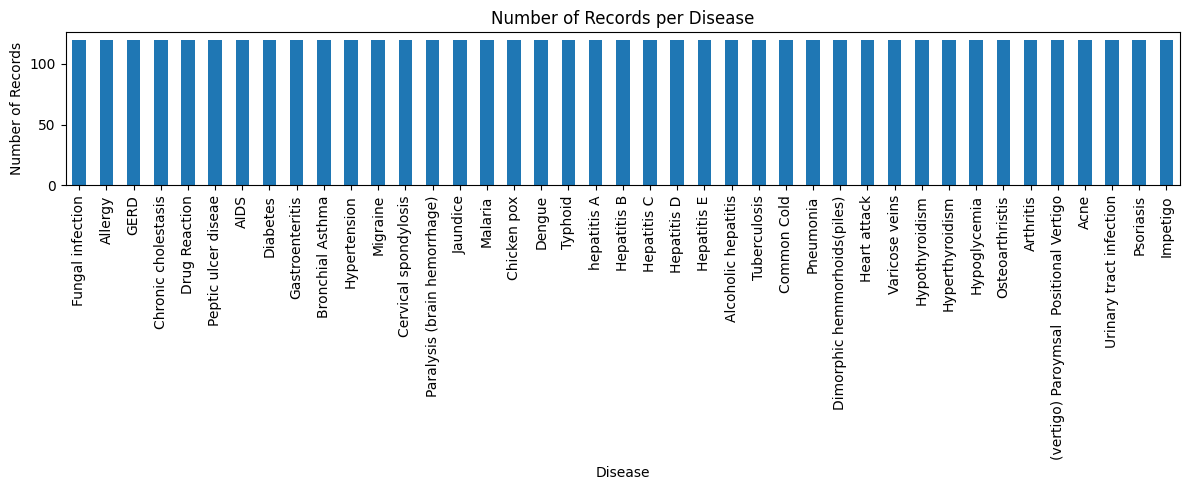

Minimum records per disease: 120
Maximum records per disease: 120


In [20]:

import matplotlib.pyplot as plt

disease_counts = df_binary["Disease"].value_counts()

plt.figure(figsize=(12, 5))
disease_counts.plot(kind="bar")
plt.title("Number of Records per Disease")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Minimum records per disease:", disease_counts.min())
print("Maximum records per disease:", disease_counts.max())


In [21]:
# Remove exact duplicate records
df_unique = df_binary.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df_binary.shape)
print("Dataset after removing duplicates:", df_unique.shape)

print("\nNumber of disease classes:", df_unique["Disease"].nunique())

print("\nRecords per disease:")
display(df_unique["Disease"].value_counts().to_frame("Records"))

Original dataset shape: (4920, 132)
Dataset after removing duplicates: (304, 132)

Number of disease classes: 41

Records per disease:


,Records
Disease,
Migraine,10
Dengue,10
Hepatitis D,10
Chicken pox,10
Typhoid,9
Hepatitis B,9
Jaundice,9
hepatitis A,9
Diabetes,9


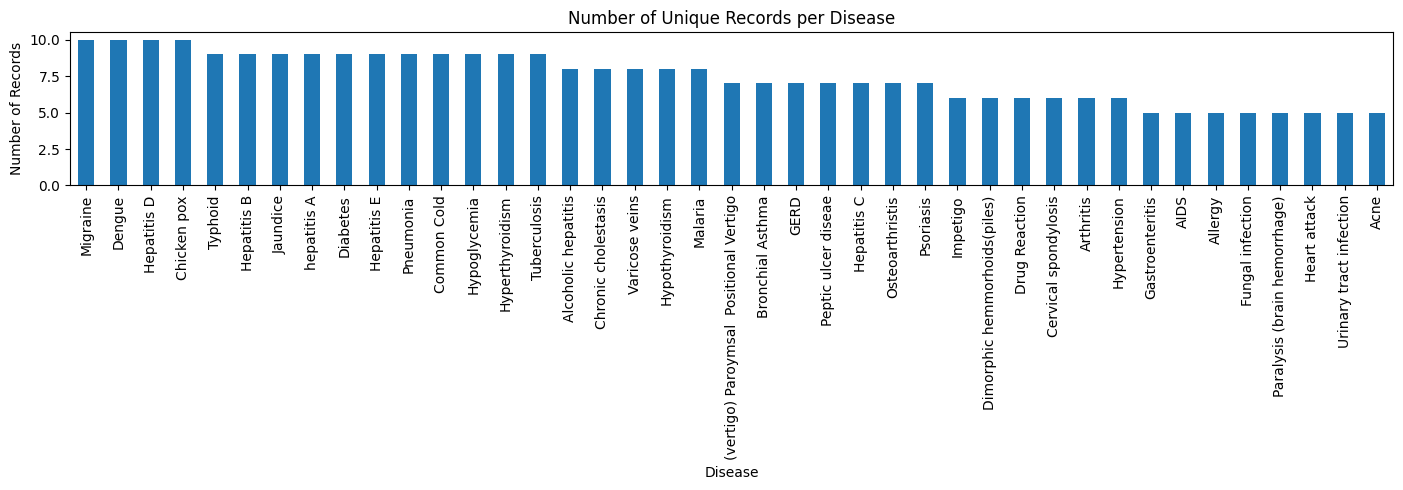

Minimum records per disease: 5
Maximum records per disease: 10


In [22]:
import matplotlib.pyplot as plt

disease_counts = df_unique["Disease"].value_counts()

plt.figure(figsize=(14, 5))
disease_counts.plot(kind="bar")

plt.title("Number of Unique Records per Disease")
plt.xlabel("Disease")
plt.ylabel("Number of Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Minimum records per disease:", disease_counts.min())
print("Maximum records per disease:", disease_counts.max())

In [23]:
df_unique.to_csv("final_symptom_disease.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [24]:
from google.colab import files

files.download("final_symptom_disease.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# Check the cleaned dataset
print("Dataset shape:", df_unique.shape)
print("Number of diseases:", df_unique["Disease"].nunique())

print("\nFirst 5 records:")
display(df_unique.head())

print("\nMissing values:", df_unique.isnull().sum().sum())

print("\nUnique values in symptom columns:")
symptom_columns = [col for col in df_unique.columns if col != "Disease"]

print(df_unique[symptom_columns].stack().unique())

Dataset shape: (304, 132)
Number of diseases: 41

First 5 records:


,Disease,abdominal_pain,abnormal_menstruation,acidity,acute_liver_failure,altered_sensorium,anxiety,back_pain,belly_pain,blackheads,...,vomiting,watering_from_eyes,weakness_in_limbs,weakness_of_one_body_side,weight_gain,weight_loss,yellow_crust_ooze,yellow_urine,yellowing_of_eyes,yellowish_skin
0,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,Fungal infection,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Missing values: 0

Unique values in symptom columns:
[0 1]


In [26]:
%pip install -q pgmpy

In [27]:
import pgmpy

print("pgmpy version:", pgmpy.__version__)
print("Bayesian Network library is ready!")

pgmpy version: 1.1.2
Bayesian Network library is ready!


In [30]:
from pgmpy.models import DiscreteBayesianNetwork

# Create the network structure
symptom_columns = [col for col in df_unique.columns if col != "Disease"]

edges = [("Disease", symptom) for symptom in symptom_columns]

model = DiscreteBayesianNetwork(edges)

print("Bayesian Network structure created successfully!")
print("Number of nodes:", len(model.nodes()))
print("Number of edges:", len(model.edges()))

Bayesian Network structure created successfully!
Number of nodes: 132
Number of edges: 131


In [32]:
from pgmpy.estimators import BayesianEstimator

# Create the Bayesian estimator
estimator = BayesianEstimator(
    model=model,
    data=df_unique
)

# Estimate the conditional probability distributions
cpds = estimator.get_parameters(
    prior_type="BDeu",
    equivalent_sample_size=10
)

# Add the probability tables to the network
model.add_cpds(*cpds)

print("Probability tables learned successfully!")
print("Number of CPDs:", len(model.get_cpds()))
print("Is the network valid?", model.check_model())

/tmp/ipykernel_984/648479710.py:4: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimator = BayesianEstimator(


Probability tables learned successfully!
Number of CPDs: 132
Is the network valid? True


In [33]:
from pgmpy.inference import VariableElimination

# Create the inference engine
inference = VariableElimination(model)

print("Inference engine created successfully!")

Inference engine created successfully!


In [34]:
# Example symptoms selected by a user
test_symptoms = ["itching", "skin_rash"]

# Check whether the symptoms exist in our dataset
for symptom in test_symptoms:
    if symptom not in symptom_columns:
        print(f"Warning: {symptom} is not in the dataset.")

print("Test symptoms:", test_symptoms)

Test symptoms: ['itching', 'skin_rash']


In [35]:
# Keep only symptoms that exist in the dataset
evidence = {
    symptom: 1
    for symptom in test_symptoms
    if symptom in symptom_columns
}

# Calculate the probability distribution over diseases
result = inference.query(
    variables=["Disease"],
    evidence=evidence,
    show_progress=False
)

# Convert results into a readable table
import pandas as pd

probabilities = pd.DataFrame({
    "Disease": result.state_names["Disease"],
    "Probability": result.values
})

probabilities["Probability (%)"] = (
    probabilities["Probability"] * 100
).round(2)

probabilities = probabilities.sort_values(
    by="Probability",
    ascending=False
).reset_index(drop=True)

print("Top 5 diseases for the selected symptoms:")
display(probabilities.head(5))

Top 5 diseases for the selected symptoms:


,Disease,Probability,Probability (%)
0,Chicken pox,0.496654,49.67
1,Drug Reaction,0.256897,25.69
2,Fungal infection,0.198105,19.81
3,Dengue,0.006640,0.66
4,Hepatitis B,0.006551,0.66


In [36]:
# Interactive symptom selection

print("MEDICAL DISEASE DIAGNOSIS")
print("-" * 35)

print("Here are some symptoms you can select:")
available_symptoms = sorted(symptom_columns)

for i, symptom in enumerate(available_symptoms[:30], start=1):
    print(f"{i}. {symptom}")

print("\nTotal available symptoms:", len(available_symptoms))

MEDICAL DISEASE DIAGNOSIS
-----------------------------------
Here are some symptoms you can select:
1. abdominal_pain
2. abnormal_menstruation
3. acidity
4. acute_liver_failure
5. altered_sensorium
6. anxiety
7. back_pain
8. belly_pain
9. blackheads
10. bladder_discomfort
11. blister
12. blood_in_sputum
13. bloody_stool
14. blurred_and_distorted_vision
15. breathlessness
16. brittle_nails
17. bruising
18. burning_micturition
19. chest_pain
20. chills
21. cold_hands_and_feets
22. coma
23. congestion
24. constipation
25. continuous_feel_of_urine
26. continuous_sneezing
27. cough
28. cramps
29. dark_urine
30. dehydration

Total available symptoms: 131


In [37]:
# Enter symptoms separated by commas
user_input = input(
    "Enter your symptoms separated by commas: "
).strip().lower()

selected_symptoms = [
    symptom.strip()
    for symptom in user_input.split(",")
    if symptom.strip()
]

# Validate the entered symptoms
valid_symptoms = [
    symptom for symptom in selected_symptoms
    if symptom in symptom_columns
]

invalid_symptoms = [
    symptom for symptom in selected_symptoms
    if symptom not in symptom_columns
]

if invalid_symptoms:
    print("These symptoms were not found:", invalid_symptoms)

if not valid_symptoms:
    print("Please run this cell again and enter valid symptoms.")
else:
    print("Selected symptoms:", valid_symptoms)

Enter your symptoms separated by commas: itching, skin_rash
Selected symptoms: ['itching', 'skin_rash']


In [38]:
if valid_symptoms:
    evidence = {symptom: 1 for symptom in valid_symptoms}

    result = inference.query(
        variables=["Disease"],
        evidence=evidence,
        show_progress=False
    )

    prediction_df = pd.DataFrame({
        "Disease": result.state_names["Disease"],
        "Probability (%)": (result.values * 100).round(2)
    })

    prediction_df = prediction_df.sort_values(
        by="Probability (%)",
        ascending=False
    ).reset_index(drop=True)

    print("Estimated disease probabilities:")
    display(prediction_df.head(5))

    print(
        "\nEducational prototype only — "
        "not a medical diagnosis."
    )

Estimated disease probabilities:


,Disease,Probability (%)
0,Chicken pox,49.67
1,Drug Reaction,25.69
2,Fungal infection,19.81
3,Hepatitis B,0.66
4,Dengue,0.66



Educational prototype only — not a medical diagnosis.


In [39]:
import pickle

# Save the trained Bayesian Network
with open("bayesian_network.pkl", "wb") as file:
    pickle.dump(model, file)

print("Bayesian Network saved successfully!")

Bayesian Network saved successfully!


In [40]:
from google.colab import files

files.download("bayesian_network.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
df_unique.to_csv("final_symptom_disease.csv", index=False)

from google.colab import files
files.download("final_symptom_disease.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>